# 01. Перевірка згенерованого датасету

Короткий sanity-check після `docker compose up --build generator`: структура, якість, наявність data drift.
Кожна перевірка — `assert`: якщо генерація зламана, ноутбук впаде.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "../data/"
customers = pd.read_csv(DATA_DIR + "telco_customers.csv", parse_dates=["RecordDate"])
conversations = pd.read_csv(DATA_DIR + "support_conversations.csv", parse_dates=["RecordDate"])
kb = pd.read_csv(DATA_DIR + "knowledge_base.csv")
print("customers:", customers.shape, "| conversations:", conversations.shape, "| kb:", kb.shape)
customers.head()

customers: (50000, 22) | conversations: (7500, 5) | kb: (8, 3)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,RecordDate
0,5817-YYUTM,Male,0,No,No,32,Yes,No,DSL,No,...,No,Yes,No,Month-to-month,Yes,Credit card (automatic),92.32,2891.80,Yes,2023-01-01
1,5670-CZKES,Male,0,Yes,Yes,15,Yes,No,DSL,No,...,No,Yes,No,Month-to-month,No,Electronic check,123.84,1907.83,Yes,2023-01-01
2,9997-PULJX,Male,1,No,No,46,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,46.38,2073.59,Yes,2023-01-01
3,7236-KXJSF,Male,0,No,Yes,54,Yes,Yes,Fiber optic,Yes,...,No,Yes,Yes,Two year,Yes,Bank transfer (automatic),154.90,8345.06,No,2023-01-01
4,3203-POHFV,Female,0,Yes,No,24,Yes,No,DSL,No,...,No,No,No,Two year,No,Electronic check,96.44,2287.38,Yes,2023-01-01


## 1. Структура та якість

In [2]:
expected = {"customerID", "tenure", "Contract", "InternetService", "PaymentMethod",
            "MonthlyCharges", "TotalCharges", "Churn", "RecordDate"}
assert expected <= set(customers.columns), expected - set(customers.columns)
assert len(customers) >= 10_000, len(customers)
assert customers["customerID"].is_unique, "дублікати customerID"
assert customers.isna().sum().sum() == 0, customers.isna().sum()[lambda s: s > 0]
assert set(customers["Churn"]) == {"Yes", "No"}
assert (customers["MonthlyCharges"] > 0).all()
assert set(conversations["customerID"]) <= set(customers["customerID"]), "розмови без клієнта"
assert len(kb) > 0

print("Період:", customers["RecordDate"].min().date(), "→", customers["RecordDate"].max().date())
print("Пропусків: 0, дублікатів ID: 0")
customers.dtypes

Період: 2023-01-01 → 2024-12-31
Пропусків: 0, дублікатів ID: 0


customerID                     str
gender                         str
SeniorCitizen                int64
Partner                        str
Dependents                     str
tenure                       int64
PhoneService                   str
MultipleLines                  str
InternetService                str
OnlineSecurity                 str
OnlineBackup                   str
DeviceProtection               str
TechSupport                    str
StreamingTV                    str
StreamingMovies                str
Contract                       str
PaperlessBilling               str
PaymentMethod                  str
MonthlyCharges             float64
TotalCharges               float64
Churn                          str
RecordDate          datetime64[us]
dtype: object

## 2. Розподіл цільової змінної

In [3]:
customers["Churn"].value_counts(normalize=True).round(3)

Churn
Yes    0.587
No     0.413
Name: proportion, dtype: float64

## 3. Data / concept drift у часі

Генератор закладає поступовий дрейф: churn падає, частка Fiber optic росте, Electronic check — падає.

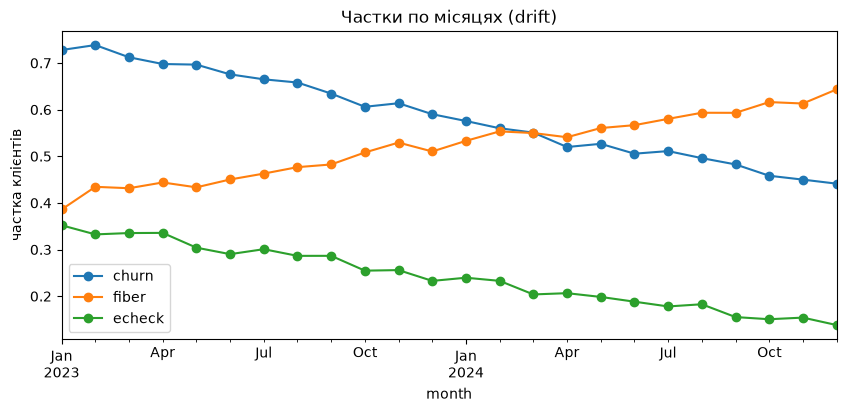

       churn  fiber  echeck
month                      
2023   0.668  0.462   0.297
2024   0.506  0.579   0.186

✅ Усі перевірки пройдено: датасет коректний, drift присутній


In [4]:
monthly = customers.assign(
    month=customers["RecordDate"].dt.to_period("M"),
    churn=customers["Churn"].eq("Yes"),
    fiber=customers["InternetService"].eq("Fiber optic"),
    echeck=customers["PaymentMethod"].eq("Electronic check"),
).groupby("month")[["churn", "fiber", "echeck"]].mean()

ax = monthly.plot(figsize=(10, 4), marker="o", title="Частки по місяцях (drift)")
ax.set_ylabel("частка клієнтів")
plt.show()

yearly = monthly.groupby(monthly.index.year).mean().round(3)
print(yearly)
first, last = yearly.iloc[0], yearly.iloc[-1]
assert last["churn"] < first["churn"], "churn мав би знижуватись"
assert last["fiber"] > first["fiber"], "Fiber optic мав би зростати"
assert last["echeck"] < first["echeck"], "Electronic check мав би падати"
print("\n✅ Усі перевірки пройдено: датасет коректний, drift присутній")